## Font de les dades

Les dades utilitzades a continuació provenen de:
* **Font:** [The Himalayan Database](https://www.himalayandatabase.com/)
* **Dataset (via):** [Kaggle](https://www.kaggle.com/datasets/siddharth0935/himalayan-expeditions)

In [2]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')
# FONT: https://www.geeksforgeeks.org/python/how-to-disable-python-warnings/

# Carrego els dos datasets en dos dataframes
exped = pd.read_csv('exped.csv')
peaks = pd.read_csv('peaks.csv')

# Uneixo els dos dataframes a través de la variable clau 'peakid'
# Utilitzo la funció merge amb inner
# FONT: https://www.geeksforgeeks.org/pandas/pandas-merge-dataframe/
df_complet = pd.merge(exped, peaks, on='peakid', how='inner')

In [3]:
# Selecciono les variables numèriques que m'interessen i
# creo un altre dataframe

variables = ['camps','heightm','mdeaths','rope',
             'smtmembers','totdays','tothired','totmembers']

df_seleccio = df_complet[variables]


# Netejo el dataframe de valor NA amb dropna() per a fer la
# correlació amb dades numèriques completes.
# FONT: https://www.w3schools.com/python/pandas/ref_df_dropna.asp

df_net = df_seleccio.dropna()

In [4]:
# Calculo el coeficient de correlació de Pearson
# FONT: https://www.geeksforgeeks.org/pandas/python-pandas-dataframe-corr/
matriu = df_net.corr()

# Utilitzo display per poder veure tot el dataframe amb un gradient de colors
# per facilitar la lectura visual
# FONT: https://www.geeksforgeeks.org/pandas/display-vs-print-in-pandas/
# FONT: https://pandas.pydata.org/docs/reference/api/pandas.io.formats.style.Styler.background_gradient.html

display(matriu.style.background_gradient(
    cmap="YlOrRd").format(precision=1))

,camps,heightm,mdeaths,rope,smtmembers,totdays,tothired,totmembers
camps,1.0,0.4,0.1,0.1,0.2,0.5,0.3,0.2
heightm,0.4,1.0,0.1,0.0,0.0,0.6,0.3,0.1
mdeaths,0.1,0.1,1.0,0.0,0.0,0.1,0.1,0.2
rope,0.1,0.0,0.0,1.0,0.0,0.1,0.1,0.2
smtmembers,0.2,0.0,0.0,0.0,1.0,0.1,0.5,0.5
totdays,0.5,0.6,0.1,0.1,0.1,1.0,0.3,0.2
tothired,0.3,0.3,0.1,0.1,0.5,0.3,1.0,0.6
totmembers,0.2,0.1,0.2,0.2,0.5,0.2,0.6,1.0


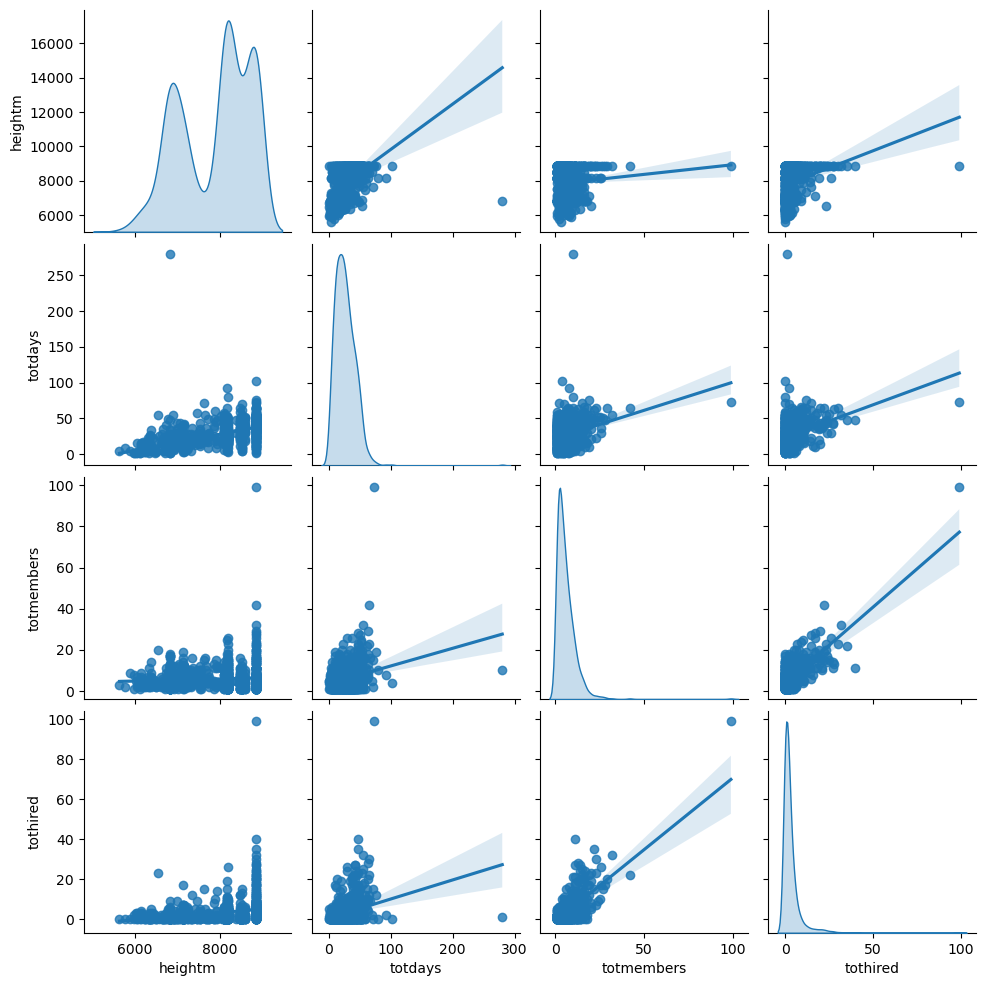

In [5]:
# Comprovo, amb un altre tipus de matriu de correlació, que
# les variables que han sortit amb correlació, visualment tenen
# una relació lineal i no és degut a una distribució fortuïta

variables_finals = ['heightm', 'totdays', 'totmembers', 'tothired']
df_cor = df_net[variables_finals]


# Faig mostreig per evitar l'overplotting.
# FONT: https://www.geeksforgeeks.org/python/python-pandas-dataframe-sample/
# Utilitzo random_state per assegurar que el resultat sigui reproduïble

df_mostres = df_cor.sample(n=1000, random_state=42)

# Aplico un correlograma tal i com explica la font.
# Per a veure com es distribueix la freqüència a la diagonal de la
# matriu, utilitzo la densitat.
# FONT: https://python-graph-gallery.com/111-custom-correlogram/

sns.pairplot(df_mostres, kind='reg',diag_kind='kde')
plt.show()